# Discounted Method

This approach is to estimate the future fundamental on a QoQ basis and then discount that value back to today's approach. We will still keep things simple and use the sample tickers and then end of the quarter statistics. 

In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

import matplotlib.pyplot as plt
from   matplotlib.ticker import FuncFormatter

In [2]:
from tqdm import tqdm
tqdm.pandas()

In [3]:
note_path  = os.getcwd()
repo_path  = os.path.abspath(os.path.join(note_path, ".."))
src_path   = os.path.join(repo_path, "src")
data_path  = os.path.join(repo_path, "data")
db_path    = os.path.join(data_path, "DataBase")
quart_path = os.path.join(db_path, "Quarterlyized")
daily_path = os.path.join(db_path, "DailyData")
model_path = os.path.join(data_path, "Models")
base_path  = os.path.join(model_path, "BaselineModels")

In [4]:
import sys
sys.path.append(src_path)
from OLSModels import OLSModels

In [5]:
sample_tickers = ['SPX Index', 'RTY Index', 'NDX Index']

In [6]:
ticker_path = os.path.join(data_path, "EquityForecastTickerGuide.xlsx")
df_renamer  = pd.read_excel(io = ticker_path, sheet_name = "Renamer")

RENAMER = (df_renamer
    .set_index("old_name")
    .loc[lambda x: x.group == "renamer"]
    .new_name
    .to_dict())

PLOT_RENAMER = (df_renamer
    .set_index("old_name")
    .loc[lambda x: x.group == "plot_renamer"]
    .assign(name = lambda x: x.new_name.str.replace(r"\\n", "\n", regex = True))
    .name
    .to_dict())

# Non-discounted method

In [7]:
path = os.path.join(base_path, "PredictiveModels.pkl")
with open(path, "rb") as f: models = pickle.load(f)
fundamental_fields = list(set([val.split("-")[1] for val in models.keys()]))

In [8]:
path = os.path.join(quart_path, "QuarterlyFundamentalEquityIndexData.parquet")

df_fundamental = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.ticker.isin(sample_tickers)]
    .loc[lambda x: x.stat_method == "last"]
    .assign(ticker = lambda x: x.ticker.str.split(" ").str[0]))

In [9]:
path = os.path.join(data_path, "EquityForecastTickerGuide.xlsx")

est_field_mapper = (pd
    .read_excel(io = path, sheet_name = "FactorGuide")
    .loc[lambda x: x.real_field.isin(fundamental_fields)]
    .set_index("est_field")
    ["real_field"]
    .to_dict())

In [10]:
path   = os.path.join(daily_path, "DailyEstimateEquityIndexData.parquet")
df_est = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.ticker.isin(sample_tickers)]
    .assign(quarter = lambda x: x.date.dt.year.astype(str) + "-Q" + x.date.dt.quarter.astype(str))
    .rename(columns = {
        "value": "est_val",
        "field": "est_field"})
    .assign(
        ticker = lambda x: x.ticker.str.split(" ").str[0], 
        field  = lambda x: x.est_field.map(est_field_mapper))
    .loc[lambda x: x.field.isin(fundamental_fields)]
    .groupby(["date", "ticker", "est_field", "field"])
    .agg("min")
    .reset_index())

In [11]:
def _quarterly_accumulate(df: pd.DataFrame) -> pd.DataFrame: 

    df_out = (df
        .sort_index()
        .assign(
            daily_add  = lambda x: x.pred_diff / 90,
            cuml_val   = lambda x: x.daily_add.cumsum(),
            pred_level = lambda x: x.cuml_val + x.value))

    return df_out

In [12]:
df_lists = []

for model_key in models.keys():

    ticker, field, stat_method = model_key.split("-")

    df_tmp_fund = (df_fundamental
        .loc[lambda x: x.field == field]
        .loc[lambda x: x.ticker == ticker]
        .loc[lambda x: x.stat_method == stat_method]
        [["quarter", "value"]])
    
    df_tmp_est = (df_est
        .loc[lambda x: x.ticker == ticker]
        .loc[lambda x: x.field == field])

    df_add = (models
        [model_key]
        .fittedvalues
        .to_frame(name = "pred_diff")
        .merge(right = df_tmp_fund, how = "inner", on = ["quarter"])
        .merge(right = df_tmp_est, how = "inner", on = ["quarter"])
        .set_index("date")
        .sort_index()
        .groupby("quarter")
        .apply(_quarterly_accumulate)
        .reset_index())

    df_lists.append(df_add)

df_out = pd.concat(df_lists)

In [13]:
def _get_adj(df: pd.DataFrame) -> pd.DataFrame: 

    df_out = (df
        [["pred_level", "est_val"]]
        .diff()
        .assign(
            pred_level = lambda x: x.pred_level / x.pred_level.ewm(span = 90, adjust = False).std(),
            est_val    = lambda x: x.est_val / x.est_val.ewm(span = 10, adjust = False).std())
        .apply(lambda x: np.where(np.abs(x) > 1e2, np.nan, x)))

    return df_out

df_prep = (df_out
    .assign(group_var = lambda x: x.ticker + " " + x.field)
    .set_index("date")
    .groupby("group_var")
    .apply(_get_adj)
    .reset_index())

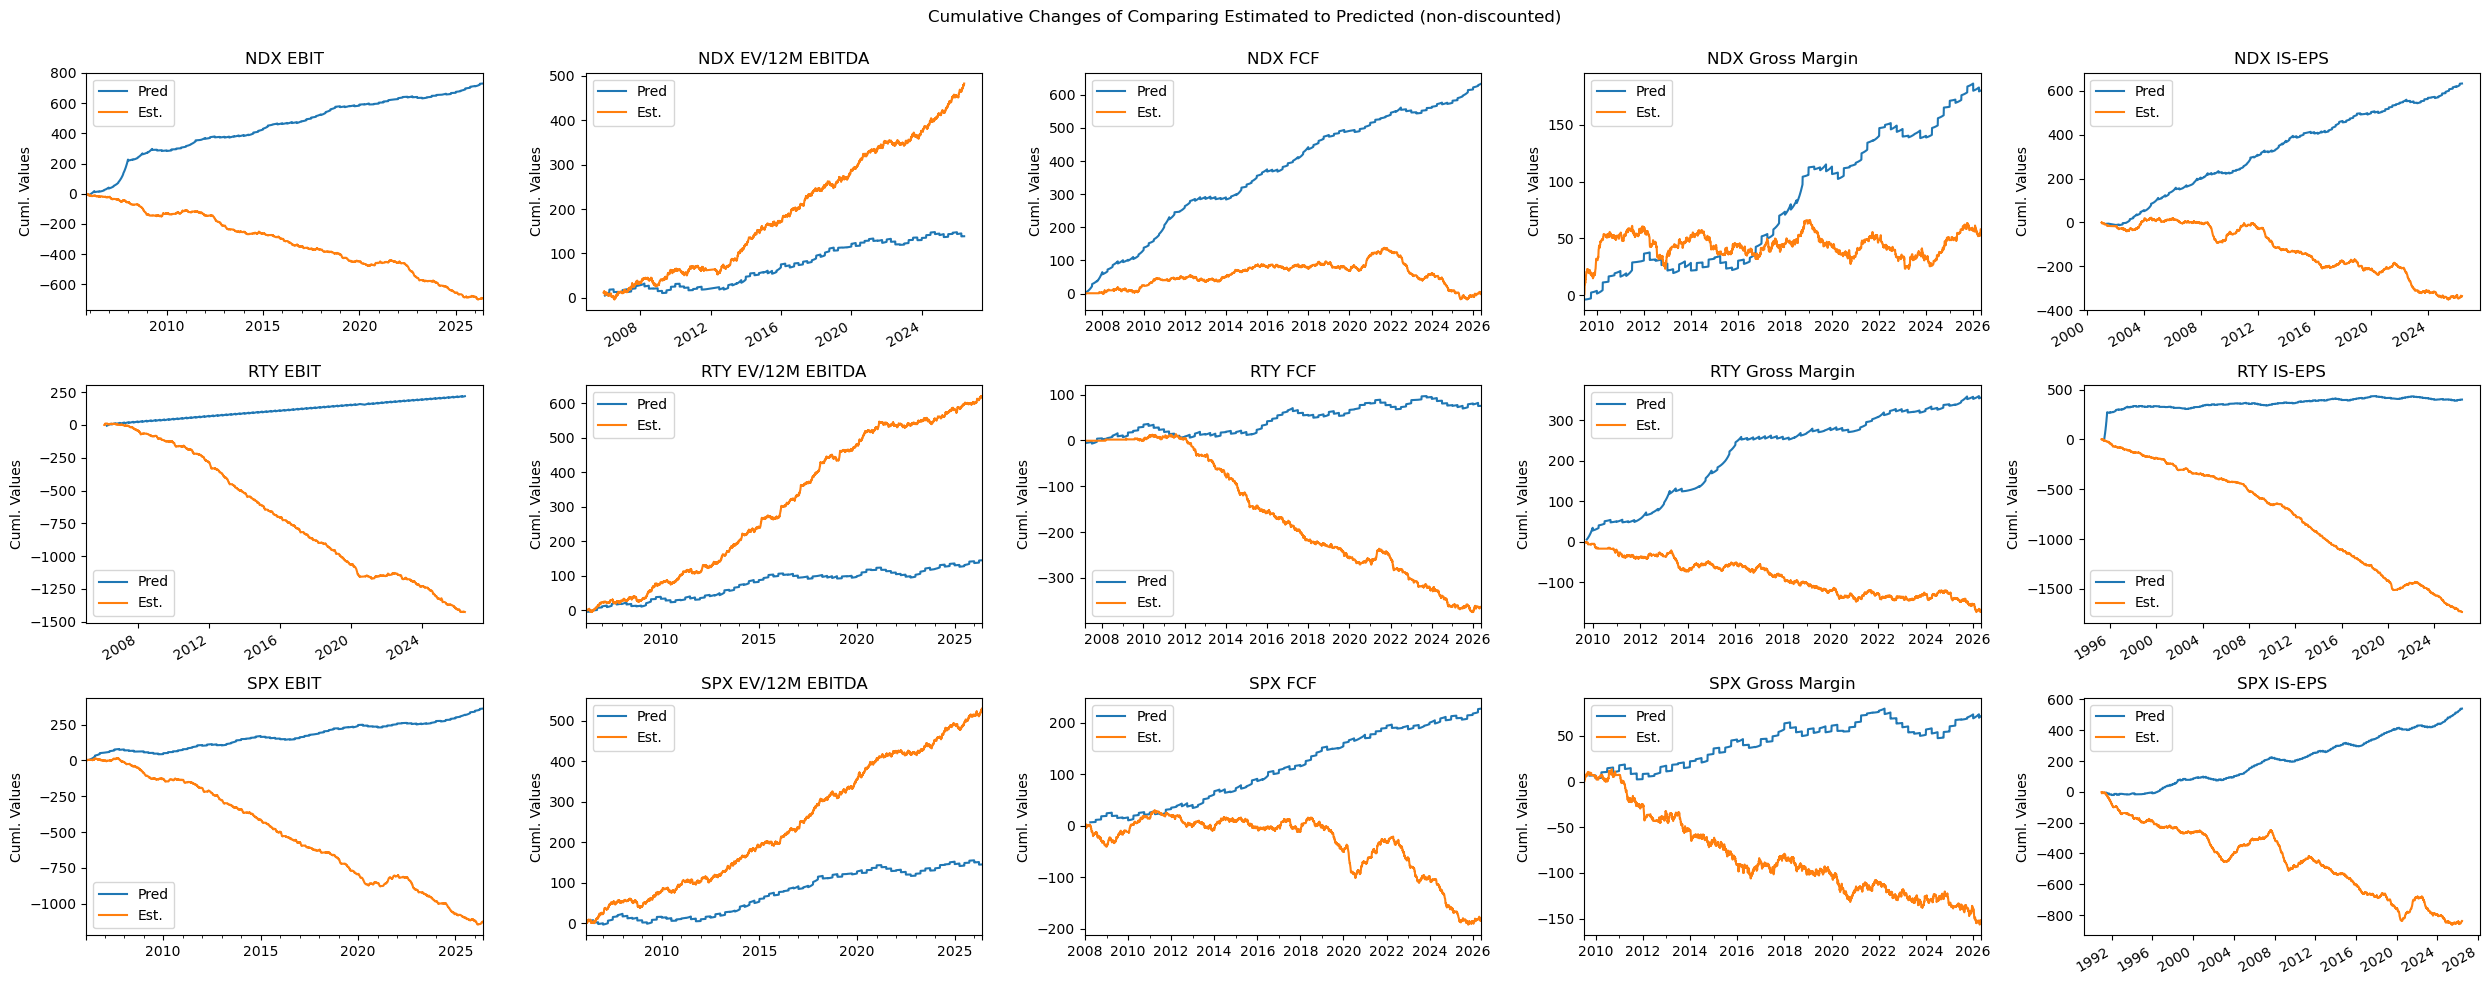

In [14]:
groups    = df_prep.group_var.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = 5, nrows = 3, figsize = (25,10))  

for group, ax in zip(groups, axes.flatten()): 

    ticker, field = group.split(" ")
    
    (df_prep
        .loc[lambda x: x.group_var == group]
        .set_index("date")
        .rename(columns = {
            "pred_level": "Pred",
            "est_val"   : "Est."})
        .cumsum()
        .plot(
            ax     = ax,
            xlabel = "",
            ylabel = "Cuml. Values",
            title  = ticker + " " + RENAMER[field]))

fig.suptitle("Cumulative Changes of Comparing Estimated to Predicted (non-discounted)\n")
plt.tight_layout()

In [15]:
path       = os.path.join(daily_path, "DailyReturnsEquityIndexData.parquet")
df_raw_rtn = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.ticker.isin(sample_tickers)]
    .loc[lambda x: x.field == "DAY_TO_DAY_TOT_RETURN_GROSS_DVDS"]
    .drop(columns = ["field"])
    .assign(value = lambda x: x.value / 100))

In [16]:
def _get_vol_rtn(df: pd.DataFrame, target: float = 0.1, window: int = 100) -> pd.DataFrame: 

    df_out = (df
        .sort_values("date")
        .assign(
            vol         = lambda x: x.value.ewm(span = window, adjust = False).std(),
            vol_rtn     = lambda x: x.value * (target / (x.vol * np.sqrt(252))),
            lag_vol_rtn = lambda x: x.value * (target / (x.vol.shift() * np.sqrt(252))))
        .drop(columns = ["vol"])
        .set_index("date"))

    return df_out

target = 0.1
window = 100

df_vol_rtn = (df_raw_rtn
    .groupby("ticker")
    .apply(_get_vol_rtn, target, window)
    .reset_index()
    .dropna()
    .rename(columns = {"value": "rtn"}))

In [17]:
df_field_longer = (df_prep
    .assign(
        ticker = lambda x: x.group_var.str.split(" ").str[0],
        field  = lambda x: x.group_var.str.split(" ").str[1])
    .drop(columns = ["group_var"])
    .melt(id_vars = ["date", "ticker", "field"], var_name = "field_type", value_name = "field_val")
    .dropna())

In [18]:
df_prep = (df_vol_rtn
    .melt(id_vars = ["ticker", "date"], value_name = "rtn_val")
    .assign(ticker = lambda x: x.ticker.str.split(" ").str[0])
    .merge(right = df_field_longer, how = "inner", on = ["date", "ticker"])
    .assign(group_var = lambda x: x.ticker + " " + x.variable + " " + x.field + " " + x.field_type))

In [19]:
group_vars =  df_prep.group_var.drop_duplicates().sort_values().to_list()
models     = {}

for group_var in group_vars: 

    df_tmp =(df_prep
        .loc[lambda x: x.group_var == group_var]
        .set_index("date"))

    model = (sm
        .OLS(
            endog = df_tmp.rtn_val,
            exog  = sm.add_constant(df_tmp.field_val))
        .fit())
    
    models[group_var] = model

In [20]:
df_params = OLSModels().get_model_params(models)

In [21]:
df_param_tmp = (df_params
    .loc[lambda x: x.param_name == "field_val"]
    .assign(
        ticker     = lambda x: x.name.str.split(" ").str[0],
        vol_target = lambda x: x.name.str.split(" ").str[1],
        field      = lambda x: x.name.str.split(" ").str[2],
        field_type = lambda x: x.name.str.split(" ").str[3]))

In [22]:
(df_param_tmp
    .replace(RENAMER)
    .replace({
        "lag_vol_rtn": "Lag Vol",
        "est_val"    : "Est.",
        "pred_level" : "Pred.",
        "rtn"        : "None",
        "vol_rtn"    : "Vol Target"})
    .rename(columns = {
        "ticker"     : "Ticker",
        "field"      : "Field",
        "vol_target" : "Vol. Target",
        "field_type" : ""})
    .pivot(index = ["Ticker", "Field"], columns = ["Vol. Target", ""], values = "r2")
    .apply(lambda x: np.round(x,5)))

Vol. Target           Lag Vol              None          Vol Target         
                         Est.    Pred.     Est.    Pred.       Est.    Pred.
Ticker Field                                                                
NDX    EBIT           0.00001  0.00002  0.00005  0.00002    0.00001  0.00001
       EV/12M EBITDA  0.46746  0.00006  0.39575  0.00003    0.47999  0.00005
       FCF            0.00013  0.00050  0.00000  0.00057    0.00017  0.00054
       Gross Margin   0.00159  0.00008  0.00126  0.00001    0.00158  0.00008
       IS-EPS         0.00049  0.00004  0.00100  0.00002    0.00048  0.00004
RTY    EBIT           0.00067  0.00016  0.00027  0.00004    0.00069  0.00018
       EV/12M EBITDA  0.44888  0.00000  0.38457  0.00010    0.45843  0.00000
       FCF            0.00020  0.00009  0.00021  0.00010    0.00020  0.00009
       Gross Margin   0.01907  0.00000  0.01152  0.00005    0.02004  0.00000
       IS-EPS         0.00157  0.00149  0.00158  0.00112    0.00151  0.00157
SPX    EBIT           0.00005  0.00011  0.00001  0.00001    0.00005  0.00012
       EV/12M EBITDA  0.57100  0.00001  0.45467  0.00002    0.59039  0.00001
       FCF            0.00026  0.00011  0.00021  0.00000    0.00027  0.00011
       Gross Margin   0.00114  0.00005  0.00325  0.00001    0.00106  0.00005
       IS-EPS         0.00419  0.00005  0.00472  0.00005    0.00426  0.00004

Almost all of the predicted moels have weak $R^2$

In [23]:
(df_param_tmp
    .drop(columns = ["name", "param_name", "r2"])
    .melt(id_vars = ["ticker", "vol_target", "field", "field_type"])
    .replace(RENAMER)
    .replace({
        "lag_vol_rtn": "Lagged",
        "rtn"        : "None",
        "vol_rtn"    : "Perf",
        "est_val"    : "Est.",
        "pred_level" : "Pred.",
        "param_val"  : "Coeff.",
        "pvalue"     : r"$p$-value",
        "tvalue"     : r"$t$-value"})
    .rename(columns = {
        "ticker"    : "Ticker",
        "field"     : "Field",
        "variable"  : "",
        "vol_target": "Vol. Target",
        "field_type": "Field Type"})
    .pivot(index = ["Ticker", "Field", "Vol. Target"], columns = ["", "Field Type"], values = "value"))

Coeff.                   $p$-value  \
Field Type                            Est.         Pred.          Est.   
Ticker Field         Vol. Target                                         
NDX    EBIT          Lagged       0.000025 -4.256123e-05  8.326023e-01   
                     None         0.000132 -9.871447e-05  6.014254e-01   
                     Perf         0.000021 -3.979604e-05  8.501630e-01   
       EV/12M EBITDA Lagged       0.005000 -8.251198e-05  0.000000e+00   
                     None         0.010008 -1.385551e-04  0.000000e+00   
                     Perf         0.004877 -7.816803e-05  0.000000e+00   
       FCF           Lagged       0.000092  2.440111e-04  4.356854e-01   
                     None         0.000040  5.781319e-04  8.775567e-01   
                     Perf         0.000101  2.442053e-04  3.702687e-01   
       Gross Margin  Lagged      -0.000346 -1.038489e-04  9.332576e-03   
                     None        -0.000629 -5.445892e-05  2.089287e-02   
                     Perf        -0.000332 -1.012217e-04  9.556683e-03   
       IS-EPS        Lagged       0.000179  6.933457e-05  7.940232e-02   
                     None         0.000621  1.082592e-04  1.239864e-02   
                     Perf         0.000172  6.724193e-05  8.215828e-02   
RTY    EBIT          Lagged      -0.000195 -1.229780e-04  6.604609e-02   
                     None        -0.000299 -1.578067e-04  2.467266e-01   
                     Perf        -0.000191 -1.248627e-04  6.213551e-02   
       EV/12M EBITDA Lagged       0.004799 -9.167111e-07  0.000000e+00   
                     None         0.010857 -2.666872e-04  0.000000e+00   
                     Perf         0.004690 -1.320270e-06  0.000000e+00   
       FCF           Lagged      -0.000122  9.906372e-05  3.309817e-01   
                     None        -0.000315  2.645952e-04  3.093708e-01   
                     Perf        -0.000120  9.544029e-05  3.230031e-01   
       Gross Margin  Lagged      -0.001003 -1.904452e-05  2.582524e-19   
                     None        -0.001748  1.642458e-04  3.170132e-12   
                     Perf        -0.000993 -2.089939e-05  3.181817e-20   
       IS-EPS        Lagged       0.000308  3.585528e-04  4.864903e-04   
                     None         0.000691  6.989036e-04  4.669026e-04   
                     Perf         0.000292  3.557851e-04  6.236787e-04   
SPX    EBIT          Lagged       0.000050  1.130799e-04  6.296201e-01   
                     None         0.000039  7.553042e-05  8.432897e-01   
                     Perf         0.000048  1.151877e-04  6.261674e-01   
       EV/12M EBITDA Lagged       0.005391  3.350738e-05  0.000000e+00   
                     None         0.009099  8.666358e-05  0.000000e+00   
                     Perf         0.005239  3.578082e-05  0.000000e+00   
       FCF           Lagged       0.000121  1.181653e-04  2.696815e-01   
                     None         0.000213 -1.071277e-05  3.215317e-01   
                     Perf         0.000116  1.160200e-04  2.674646e-01   
       Gross Margin  Lagged       0.000256 -7.927799e-05  2.826913e-02   
                     None         0.000735  6.772040e-05  2.087525e-04   
                     Perf         0.000236 -7.498156e-05  3.410484e-02   
       IS-EPS        Lagged       0.000470 -8.139873e-05  1.221632e-09   
                     None         0.000888 -1.499495e-04  1.140593e-10   
                     Perf         0.000455 -7.481825e-05  9.210249e-10   

                                            $t$-value            
Field Type                           Pred.       Est.     Pred.  
Ticker Field         Vol. Target                                 
NDX    EBIT          Lagged       0.776457   0.211376 -0.283954  
                     None         0.762993   0.522384 -0.301569  
                     Perf         0.782760   0.188920 -0.275739  
       EV/12M EBITDA Lagged       0.599106  66.407991 -0.525720  
                     

In [24]:
df_tmp = (df_param_tmp
    .loc[lambda x: x.vol_target == "vol_rtn"]
    [["tvalue", "ticker", "field", "field_type"]])

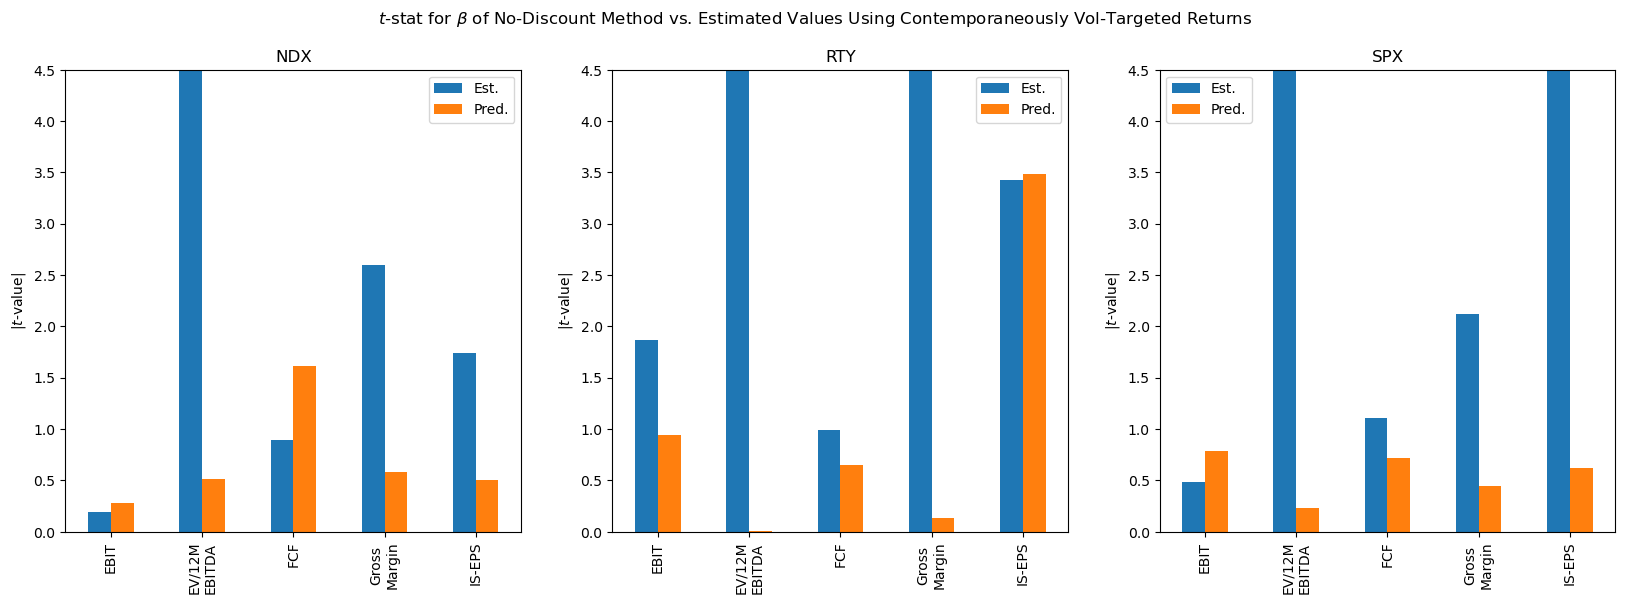

In [25]:
tickers = df_tmp.ticker.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(tickers), figsize = (20,6))

for ticker, ax in zip(tickers, axes.flatten()):

    (df_tmp
        .loc[lambda x: x.ticker == ticker]
        .replace(RENAMER)
        .replace(PLOT_RENAMER)
        .rename(columns = {"field_type": ""})
        .pivot(index = "field", columns = "", values = "tvalue")
        .rename(columns = {
            "est_val"   : "Est.",
            "pred_level": "Pred."})
        .abs()
        .plot(
            ax     = ax,
            kind   = "bar",
            ylabel = r"|$t$-value|",
            xlabel = "",
            title  = ticker))

    ax.set_ylim(top = 4.5)

fig.suptitle(r"$t$-stat for $\beta$ of No-Discount Method vs. Estimated Values Using Contemporaneously Vol-Targeted Returns")
plt.show()

# Discounted Method

In [26]:
path   = r"A:\2026BlpAdHocData\Combined\FixedIncomeIndex\INDEX_YIELD_TO_MATURITY.parquet"
df_yld = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.security == "LBUSTRUU Index"]
    .set_index("date")
    .rename(columns = {"INDEX_YIELD_TO_MATURITY": "ytm"})
    .drop(columns = ["security"])
    .assign(lag_ytm = lambda x: x.ytm.shift())
    .dropna())

In [27]:
df_non_dcf = (df_out
    .assign(
        group_var = lambda x: x.ticker + " " + x.field))

In [28]:
group_vars  = df_non_dcf.group_var.drop_duplicates().sort_values().to_list()
df_dcf_list = []

for group_var in group_vars: 

    df_add = (df_non_dcf
        .loc[lambda x: x.group_var == group_var]
        .merge(right = df_yld, how = "inner", on = ["date"])
        .assign(
            day_num       = lambda x: x.groupby("quarter").cumcount(),
            n_days        = lambda x: x.groupby("quarter")["date"].transform("size"),
            days_left     = lambda x: x.n_days - x.day_num - 1,
            discount      = lambda x: (1 + (x.lag_ytm / 360) / 100) ** (x.days_left / 252),
            pv_daily_add  = lambda x: x.daily_add / x.discount,
            pv_cuml       = lambda x: x.groupby("quarter").pv_daily_add.cumsum(),
            pv_pred_level = lambda x: x.value + x.pv_cuml)
        .set_index("date"))
    
    df_dcf_list.append(df_add)

In [29]:
df_dcf = pd.concat(df_dcf_list)

In [30]:
def _get_adj(df: pd.DataFrame) -> pd.DataFrame:

    df_out = (df
        [["pv_pred_level", "pred_level"]]
        .diff()
        .apply(lambda x: x / x.ewm(span = 90, adjust = False).std())
        .apply(lambda x: np.where(np.abs(x) > 1, np.nan, x)))

    return df_out

df_adj = (df_dcf
    .assign(group_var = lambda x: x.ticker + " " + x.field)
    .groupby("group_var")
    .apply(_get_adj)
    .reset_index()
    .assign(
        ticker = lambda x: x.group_var.str.split(" ").str[0],
        field  = lambda x: x.group_var.str.split(" ").str[1]))

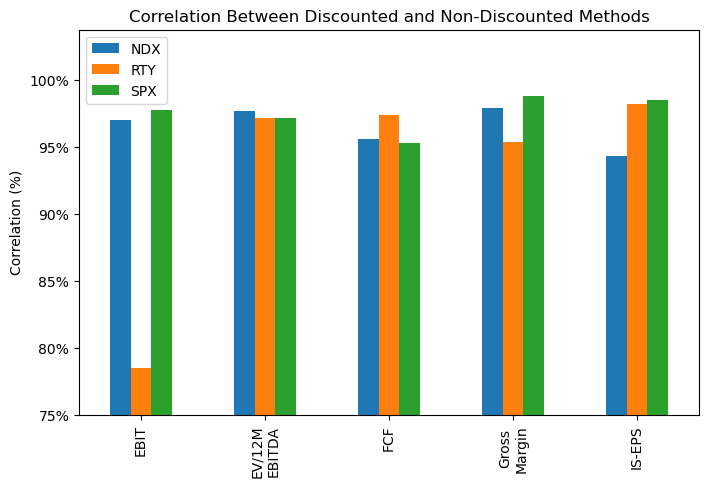

In [31]:
_, axes = plt.subplots(figsize = (8,5))

(df_adj
    .drop(columns = ["group_var", "date"])
    .groupby(["ticker", "field"])
    .agg("corr")
    .loc[lambda x: x.pred_level != 1]
    .reset_index()
    .replace(RENAMER)
    .replace(PLOT_RENAMER)
    .rename(columns = {"ticker": ""})
    .pivot(index = "field", columns = "", values = "pred_level")
    .plot(
        ax     = axes,
        kind   = "bar",
        xlabel = "",
        ylabel = "Correlation (%)",
        title  = "Correlation Between Discounted and Non-Discounted Methods",
        ylim   = 0.75))

axes.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))

In [32]:
df_rtn_longer = (df_vol_rtn
    .assign(ticker = lambda x: x.ticker.str.split(" ").str[0])
    .melt(id_vars = ["date", "ticker"], var_name = "vol_target", value_name = "rtn_val"))

In [33]:
df_combined = (df_adj
    .drop(columns = ["group_var"])
    .melt(id_vars = ["date", "ticker", "field"])
    .dropna()
    .merge(right = df_rtn_longer, how = "inner", on = ["date", "ticker"])
    .assign(group_var = lambda x: x.ticker.str.split(" ").str[0] + " " + x.field + " " + x.vol_target + " " + x.variable))

In [34]:
groups = df_combined.group_var.drop_duplicates().sort_values().to_list()
models = {}

for group in groups: 

    df_tmp = (df_combined
        .loc[lambda x: x.group_var == group]
        .set_index("date")
        [["value", "rtn_val"]]
        .dropna())

    model = (sm
        .OLS(
            endog = df_tmp.rtn_val,
            exog  = sm.add_constant(df_tmp.value))
        .fit())

    models[group] = model

In [35]:
df_params = OLSModels().get_model_params(models)

In [36]:
df_param_prep = (df_params
    .loc[lambda x: x.param_name == "value"]
    .assign(
        str_split  = lambda x: x.name.str.split(" "),
        ticker     = lambda x: x.str_split.str[0],
        field      = lambda x: x.str_split.str[1],
        vol_target = lambda x: x.str_split.str[2],
        var_type   = lambda x: x.str_split.str[3])
    .drop(columns = ["str_split"]))

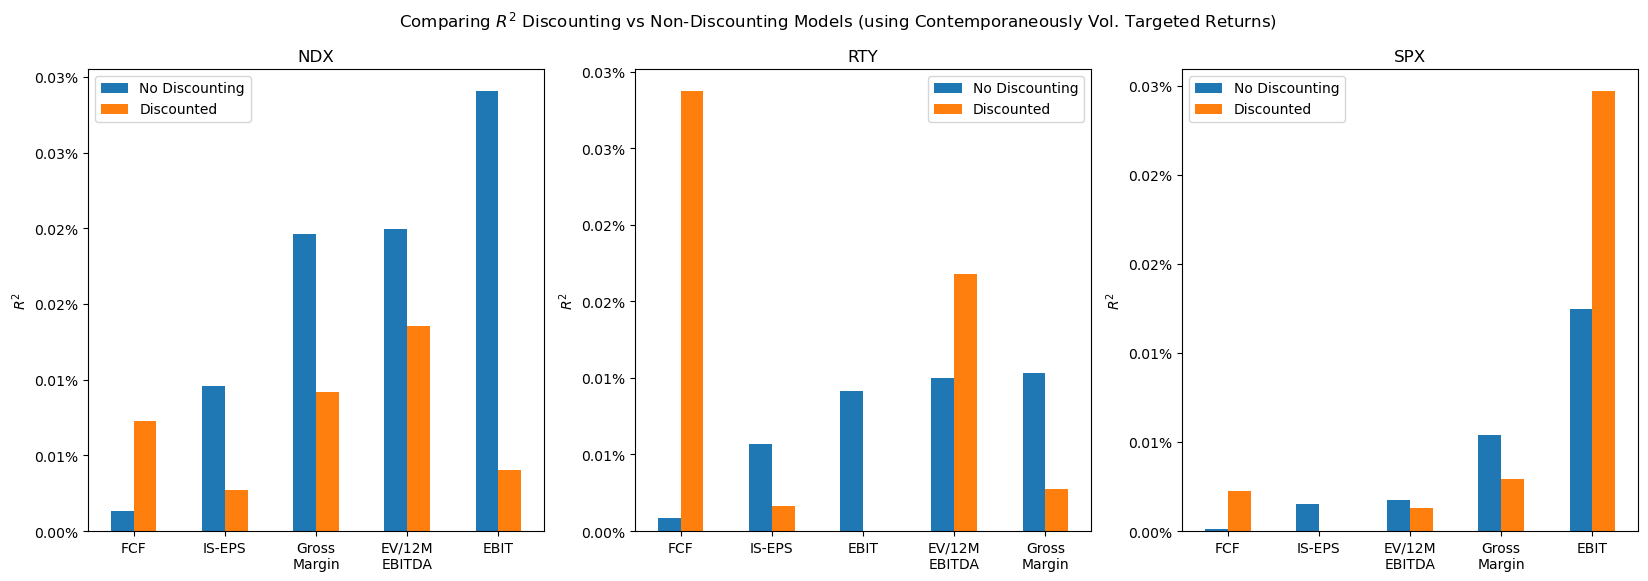

In [37]:
df_plot   = df_param_prep.assign(group_var = lambda x: x.field + " " + x.ticker)
tickers   = df_plot.ticker.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(tickers), figsize = (20,6))

for ticker,ax in zip(tickers, axes.flatten()): 

    (df_plot
        .loc[lambda x: x.vol_target == "vol_rtn"]
        .loc[lambda x: x.ticker == ticker]
        .replace(RENAMER)
        .replace(PLOT_RENAMER)
        .rename(columns = {"var_type": ""})
        .pivot(index = "field", columns = "", values = "r2")
        .sort_values("pred_level")
        .rename(columns = {
            "pred_level"   : "No Discounting",
            "pv_pred_level": "Discounted"})
        .plot(
            ax     = ax,
            kind   = "bar",
            rot    = 0,
            xlabel = "",
            title  = ticker,
            ylabel = r"$R^2$"))

    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.2%}"))

fig.suptitle("Comparing $R^2$ Discounting vs Non-Discounting Models (using Contemporaneously Vol. Targeted Returns)")
plt.show()

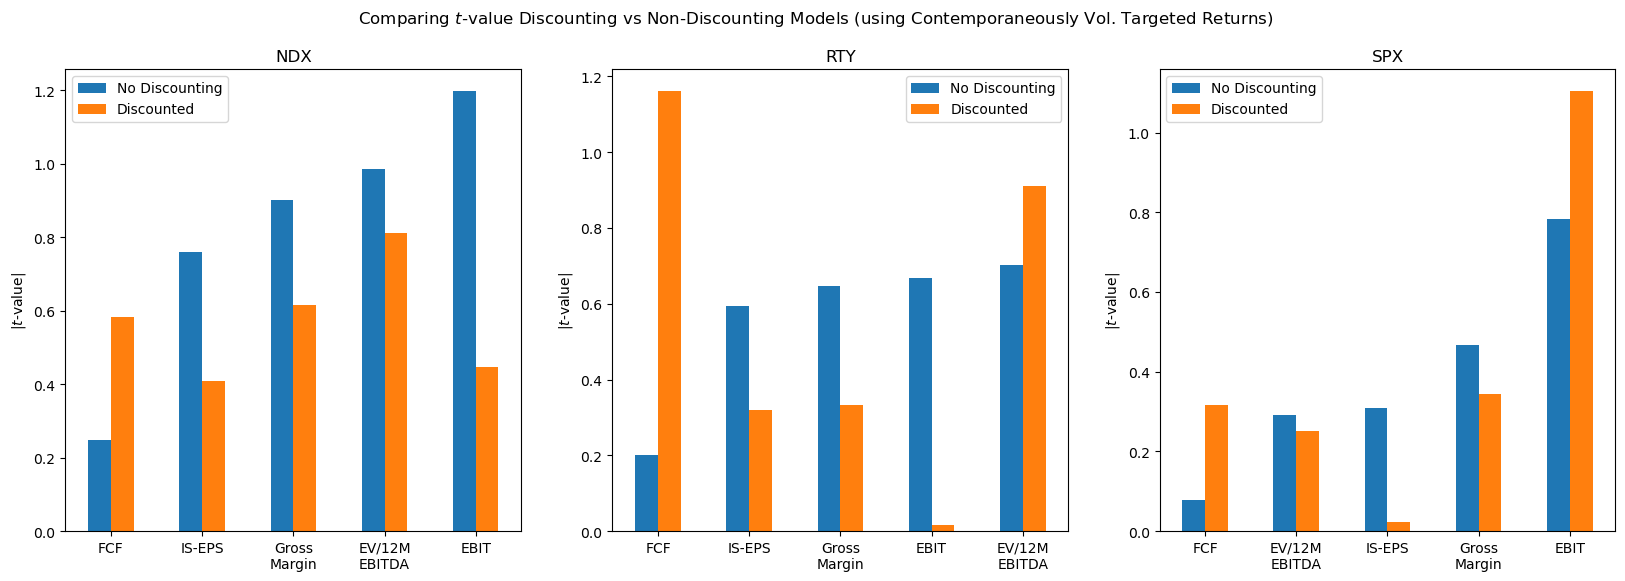

In [38]:
tickers   = df_plot.ticker.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(tickers), figsize = (20,6))

for ticker,ax in zip(tickers, axes.flatten()): 

    (df_plot
        .loc[lambda x: x.vol_target == "vol_rtn"]
        .loc[lambda x: x.ticker == ticker]
        .replace(RENAMER)
        .replace(PLOT_RENAMER)
        .rename(columns = {"var_type": ""})
        .pivot(index = "field", columns = "", values = "tvalue")
        .abs()
        .sort_values("pred_level")
        .rename(columns = {
            "pred_level"   : "No Discounting",
            "pv_pred_level": "Discounted"})
        .plot(
            ax     = ax,
            kind   = "bar",
            rot    = 0,
            xlabel = "",
            title  = ticker,
            ylabel = r"|$t$-value|"))

fig.suptitle("Comparing $t$-value Discounting vs Non-Discounting Models (using Contemporaneously Vol. Targeted Returns)")
plt.show()